## Bond Pricing, Duration & Convexity


Measuring interest rate risk with the key fixed income metrics.

<br>


<p style="margin-bottom:-8px"><b>Key Highlights:</b></p>

- A bond is a stream of promised cash flows, so its price is a question of **discounting**.
- **Duration** is the bond's delta: the first-order sensitivity of price to yield.
- **Convexity** is its gamma — the curvature correction, and it works, for option-free bonds, in the holder's favour.
- Together they summarize the cash-flow schedule into 2 numbers of the risk report.
- 2022 turned the theory into a live experiment: the same rate shock hit short and long bonds differently.

<br>

[*Content format: Tutorial (T) · Category: Quant Foundations & Derivatives (1)*   =====================> insert project card]

<br>


<p style="margin-bottom:-8px"><b>Table of Content:</b></p>

<ol>
  <li><span style="display:inline-block;width:180px"><b>Introduction</b></span>(bond pricing in a nutshell)</li>
  <li><span style="display:inline-block;width:180px"><b>Intuition</b></span>(why prices fall when yields rise, and why long bonds fall hardest)</li>
  <li><span style="display:inline-block;width:180px"><b>Theory</b></span>(the pricing formula, duration and convexity)</li>
  <li><span style="display:inline-block;width:180px"><b>Application</b></span>(the Treasury curve and the SHY / IEF / TLT reality check of 2022)</li>
  <li><span style="display:inline-block;width:180px"><b>Conclusion</b></span>(strengths, limitations, and where to go next)</li>
</ol>

In [1]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducibility (standard arbitrary number)
plt.rcParams["figure.dpi"] = 110

# ---- house style ---------------------------------------------------------
BG    = "#F4F2E8"   # Pale Sisal
INK   = "#151515"   # Anthracite
AQUA  = "#1FFFFF"   # accent
GREY  = "#7A7A7A"

HEAD  = {"fontname": "Switzer", "fontsize": 11, "fontweight": "bold", "color": INK}
SUB   = {"fontname": "Switzer", "fontsize": 9,  "fontweight": "bold", "color": INK}

plt.rcParams.update({
    "font.family": "monospace",
    "font.monospace": ["Courier Prime", "Courier New", "DejaVu Sans Mono"],
    "font.size": 8,
    "axes.titlesize": 11, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.color": "#CCCCCC", "grid.linewidth": 0.5,
    "legend.frameon": False,
    "lines.linewidth": 2.0, "lines.markersize": 0,
})

### 1. Introduction

A few simple facts to get up to speed:

- A bond's price is the **present value** of its coupons and principal, discounted at the yield to maturity.

- Price and yield move **inversely**, and the relationship is *curved*, not straight.

- **2 numbers** summarise that relationship — both computable from the cash-flow schedule alone:  
– **duration** $D$ (the slope: % price change per 1% yield change)  
– **convexity** $C$ (the curvature: how the slope itself changes)

### 2. Intuition

The logic before diving into equations:

- **Discounting, not sentiment**<br>
– When market yields rise from 2% to 4%, a bond still paying 2% coupons is simply a worse deal.<br>
– Its price falls until a new buyer earns the *current* market yield.<br>
– Nothing behavioural is involved — it is arithmetic on fixed cash flows.

- **Macaulay Duration is the weighted average waiting time to receive a bond's cash flows**<br>
– Each cash flow is weighted by its share of present value, then averaged by the time you wait for it.<br>
– A 30-year bond makes you wait decades, so a small yield change compounds over a long horizon.<br>
– Rule of thumb (Modified Duration): a bond changes roughly -$D \times \Delta y$ per   cent when yields rise by $\Delta y$.

- **Convexity is the holder's friend**<br>
– The price-yield curve bends upward, so losses from rising yields are *smaller* than the straight-line estimate.<br>
– Gains from falling yields are correspondingly *larger*.<br>
– Long bonds have the most convexity — which is why duration alone increasingly misleads for big moves.

### 3. Theory

Below the theoretical foundation and respective equations:

- **The pricing formula**  
– Face $F$, annual coupon rate $c$ paid $f$ times a year, yield $y$, and $n = fT$ periods.  
$P = \displaystyle\sum_{i=1}^{n} \frac{cF/f}{(1+y/f)^i} + \frac{F}{(1+y/f)^n}$

- **Duration and convexity**  
– Macaulay duration is the PV-weighted average time to a cash flow; modified duration rescales it into a price sensitivity.  
$D_{mac} = \dfrac{1}{P}\sum_i t_i\,PV(CF_i), \qquad D = \dfrac{D_{mac}}{1+y/f}, \qquad C = \dfrac{1}{P}\dfrac{\partial^2 P}{\partial y^2}$

- **The second-order approximation**  
– This is the equation risk reports actually use — duration for the slope, convexity for the correction.  
$\dfrac{\Delta P}{P} \approx -D\,\Delta y + \tfrac{1}{2}C\,(\Delta y)^2$

The two functions below implement this: one returns the **price**, the other the **sensitivities** by central difference.

In [2]:
# Implementation

def bond_price(face, coupon, y, T, freq=2):
    """Price of a fixed-coupon bond (coupon = annual rate, y = yield to maturity)."""
    n  = int(round(T * freq))
    t  = np.arange(1, n + 1)
    cf = np.full(n, face * coupon / freq)
    cf[-1] += face
    return float(np.sum(cf / (1 + y / freq) ** t))

def duration_convexity(face, coupon, y, T, freq=2, h=1e-4):
    """Modified duration (years) and convexity, by central difference."""
    p0   = bond_price(face, coupon, y,     T, freq)
    p_up = bond_price(face, coupon, y + h, T, freq)
    p_dn = bond_price(face, coupon, y - h, T, freq)
    dur  = -(p_up - p_dn) / (2 * h * p0)
    conv =  (p_up - 2 * p0 + p_dn) / (h ** 2 * p0)
    return dur, conv

p    = bond_price(100, 0.04, 0.04, 10)
d, k = duration_convexity(100, 0.04, 0.04, 10)
print(f"10y 4% bond priced at par: P = {p:.2f}   duration = {d:.2f}y   convexity = {k:.1f}")

10y 4% bond priced at par: P = 100.00   duration = 8.18y   convexity = 78.9


### 4. Application

- **The price-yield curve, by maturity**  
– Same 4% coupon, 3 maturities, plotted across a wide yield range.  
– Watch the **slope** (longer = steeper = more duration) and the **curvature** (longer = more convex).

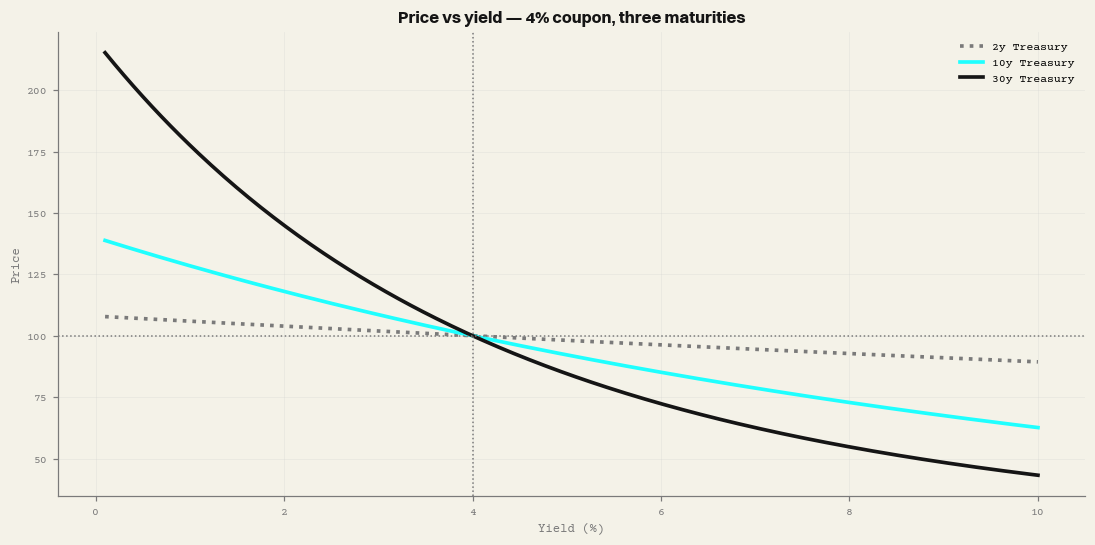

In [3]:
yields = np.linspace(0.001, 0.10, 300)

fig, ax = plt.subplots(figsize=(10, 5))
for T, colour, style in [(2, GREY, ":"), (10, AQUA, "-"), (30, INK, "-")]:
    prices = [bond_price(100, 0.04, y, T) for y in yields]
    ax.plot(yields * 100, prices, color=colour, ls=style, lw=2.4, label=f"{T}y Treasury")
ax.axhline(100, color=GREY, lw=1.0, ls=":")
ax.axvline(4,   color=GREY, lw=1.0, ls=":")
ax.set_title("Price vs yield — 4% coupon, three maturities", **HEAD)
ax.set_xlabel("Yield (%)"); ax.set_ylabel("Price"); ax.legend()
plt.tight_layout(); plt.show()

- **The duration ladder** — 1 shock, 6 maturities  
– A parallel +100bp move applied across the curve, priced exactly rather than approximated.  
– Duration rises with maturity, and so does the damage — this table *is* the risk report.

In [4]:
rows = []
for T in [1, 2, 5, 10, 20, 30]:
    d, k = duration_convexity(100, 0.04, 0.04, T)
    p0   = bond_price(100, 0.04, 0.04, T)
    p1   = bond_price(100, 0.04, 0.05, T)            # +100bp, exact repricing
    rows.append([T, round(d, 2), round(k, 1), f"{(p1/p0 - 1)*100:6.2f}%"])

ladder = pd.DataFrame(rows, columns=["Maturity (y)", "Mod. duration",
                                     "Convexity", "Exact dP for +100bp"])
print(ladder.to_string(index=False))

 Maturity (y)  Mod. duration  Convexity Exact dP for +100bp
            1           0.97        1.4              -0.96%
            2           1.90        4.6              -1.88%
            5           4.49       23.5              -4.38%
           10           8.18       78.9              -7.79%
           20          13.68      239.9             -12.55%
           30          17.38      420.8             -15.45%


- **Reality check: SHY, IEF and TLT in 2022**  
– 2022 was the worst bond year in modern history: the 2y yield rose ~370bp, the 10y ~237bp, the 30y ~207bp.  
– The three Treasury ETFs carry durations of roughly **1.9 / 7.5 / 17.5** years, so their losses should rank accordingly.  
– The gap between predicted $-D\Delta y$ and realised return is itself the lesson: coupon carry, convexity and the fact that ETFs hold *rolling* portfolios all live in that residual.

ETF    duration   dY 2022   predicted    actual
SHY         1.9     3.70%       -7.0%     -3.9%
IEF         7.5     2.37%      -17.8%    -15.2%
TLT        17.5     2.07%      -36.2%    -31.2%


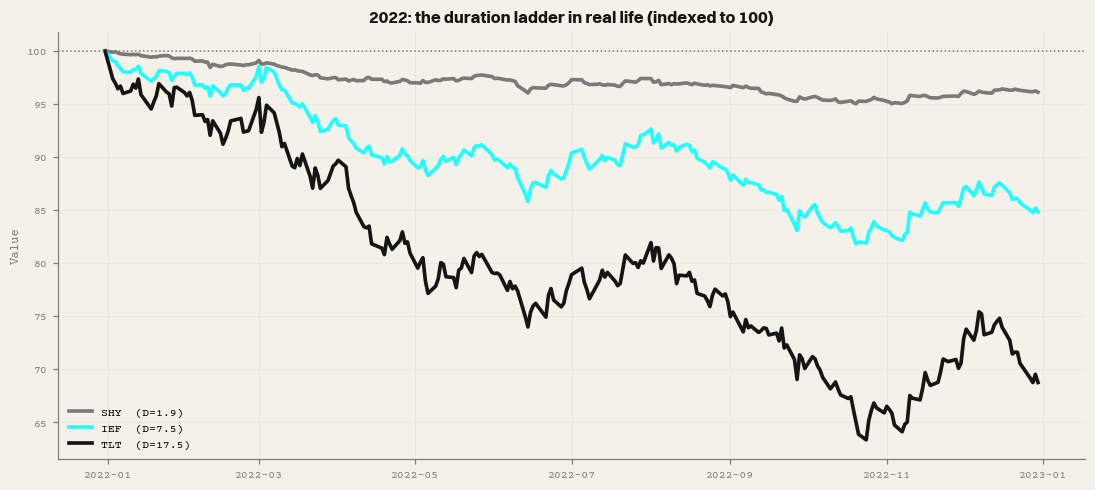

In [5]:
import yfinance as yf

etfs = {"SHY": (1.9, 0.0370), "IEF": (7.5, 0.0237), "TLT": (17.5, 0.0207)}  # (duration, 2022 dY)

px = (yf.download(list(etfs), start="2021-12-31", end="2022-12-31",
                  auto_adjust=True, progress=False)["Close"]
        .dropna())
total_ret = px.iloc[-1] / px.iloc[0] - 1

print(f"{'ETF':5}{'duration':>10}{'dY 2022':>10}{'predicted':>12}{'actual':>10}")
for t, (d, dy) in etfs.items():
    print(f"{t:5}{d:10.1f}{dy:10.2%}{-d*dy:12.1%}{total_ret[t]:10.1%}")

fig, ax = plt.subplots(figsize=(10, 4.5))
for t, colour in zip(["SHY", "IEF", "TLT"], [GREY, AQUA, INK]):
    ax.plot(px.index, px[t] / px[t].iloc[0] * 100, color=colour, lw=2.4, label=f"{t}  (D={etfs[t][0]})")
ax.axhline(100, color=GREY, lw=1.0, ls=":")
ax.set_title("2022: the duration ladder in real life (indexed to 100)", **HEAD)
ax.set_ylabel("Value"); ax.legend()
plt.tight_layout(); plt.show()

- **Sanity check:** how good is the approximation?  
– Duration alone is a straight line; adding convexity bends it toward the true price curve.  
– **How to read the result:** the two approximations are indistinguishable for small shocks and diverge visibly beyond roughly ±100bp.  
– The duration-only line always sits *below* the exact curve — it overstates losses and understates gains, which is convexity working for the holder.

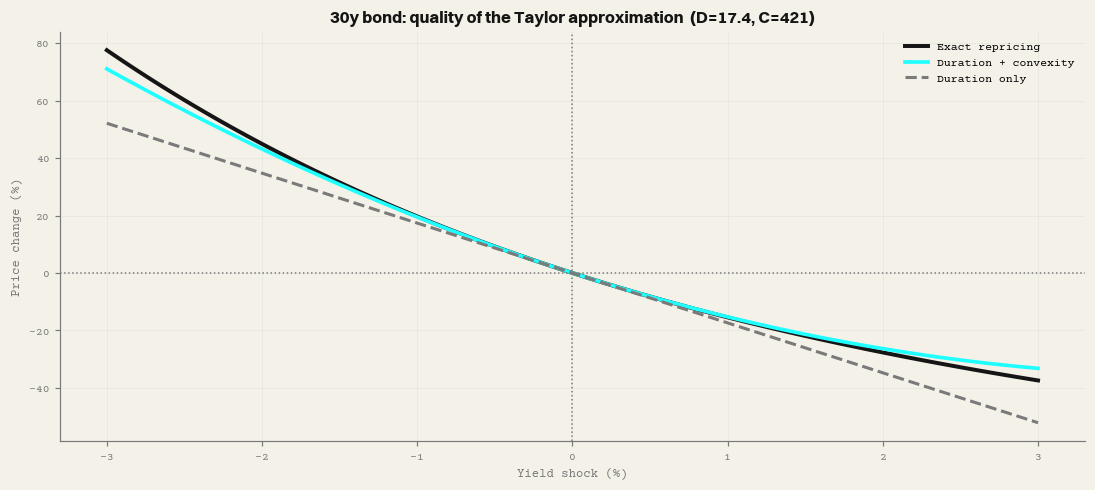

+200bp:  exact -27.68%   duration-only -34.76%   duration+convexity -26.34%


In [6]:
T    = 30
p0   = bond_price(100, 0.04, 0.04, T)
d, k = duration_convexity(100, 0.04, 0.04, T)

shocks = np.linspace(-0.03, 0.03, 121)
exact  = np.array([bond_price(100, 0.04, 0.04 + s, T) / p0 - 1 for s in shocks])
lin    = -d * shocks
quad   = -d * shocks + 0.5 * k * shocks ** 2

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(shocks * 100, exact * 100, color=INK,  lw=2.6,          label="Exact repricing")
ax.plot(shocks * 100, quad  * 100, color=AQUA, lw=2.4,          label="Duration + convexity")
ax.plot(shocks * 100, lin   * 100, color=GREY, lw=2.0, ls="--", label="Duration only")
ax.axhline(0, color=GREY, lw=1.0, ls=":"); ax.axvline(0, color=GREY, lw=1.0, ls=":")
ax.set_title(f"30y bond: quality of the Taylor approximation  (D={d:.1f}, C={k:.0f})", **HEAD)
ax.set_xlabel("Yield shock (%)"); ax.set_ylabel("Price change (%)"); ax.legend()
plt.tight_layout(); plt.show()

s = 0.02
print(f"+200bp:  exact {bond_price(100,0.04,0.06,T)/p0-1:+.2%}   "
      f"duration-only {-d*s:+.2%}   duration+convexity {-d*s+0.5*k*s*s:+.2%}")

### 5. Conclusion

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Strengths</p>

- **Three numbers, any bond** — price, duration and convexity summarise an entire cash-flow schedule
- **Excellent first-order accuracy** — duration is the industry's daily risk language for good reason
- **Convexity keeps it honest** — the correction holds the approximation together out to large shocks
- **Model-free verification** — 2022 ETF returns line up with durations straight from public data

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Weaknesses & Limitations</p>

- **Parallel-shift assumption** — real curves twist and steepen rather than moving in lockstep
- **Constant reinvestment** — yield to maturity assumes coupons are reinvested at the same rate
- **No credit** — this is a pure rates framework; spreads and default risk need their own layer
- **ETF is not a single bond** — rolling portfolios carry roll-down and carry effects the formula misses

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Applications in Practice</p>

- Portfolio duration targeting and liability immunisation
- The ±100bp rate-shock tables in every institutional risk report
- Barbell versus bullet trades, where convexity is the entire argument

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Alternatives & Extensions</p>

- **Key-rate durations** — sensitivity to individual points on the curve rather than a parallel shift
- **Yield-curve bootstrapping** — building the discount curve instead of assuming a single yield
- **Term-structure models** — Vasicek, Hull-White and CIR simulate rates rather than shocking them
- **Credit risk** — hazard rates and spread duration for anything that can default